In [32]:
import random
import numpy as np 
import tensorflow as tf 
from tensorflow import keras
from keras import layers,models
import matplotlib.pyplot as plt

In [33]:
x_train = np.load("mnist.npz/x_train.npy")
y_train = np.load("mnist.npz/y_train.npy")
x_test = np.load("mnist.npz/x_test.npy")
y_test = np.load("mnist.npz/y_test.npy")

print(x_train.shape)
print(y_train.shape) 
print(x_test.shape) 
print(y_test.shape) 

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [35]:
x_train = x_train / 255.0
x_test = x_test / 255.0 

In [36]:
model = models.Sequential([ 
    layers.Input(shape = (28,28)), 
    layers.Flatten(), 
    layers.Dense(256, activation='relu'), 
    layers.Dense(128, activation='relu'), 
    layers.Dense(64, activation='relu'), 
    layers.Dense(10, activation='softmax') 
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(
    optimizer= keras.optimizers.SGD(learning_rate=0.01),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)
    
    

In [38]:
history = model.fit(
    x_train, y_train,
    epochs = 25, 
    validation_split=0.1
)

Epoch 1/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8407 - loss: 0.6072 - val_accuracy: 0.9263 - val_loss: 0.2635
Epoch 2/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9224 - loss: 0.2659 - val_accuracy: 0.9465 - val_loss: 0.1983
Epoch 3/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9391 - loss: 0.2107 - val_accuracy: 0.9555 - val_loss: 0.1593
Epoch 4/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9497 - loss: 0.1739 - val_accuracy: 0.9590 - val_loss: 0.1386
Epoch 5/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9565 - loss: 0.1474 - val_accuracy: 0.9615 - val_loss: 0.1275
Epoch 6/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9626 - loss: 0.1280 - val_accuracy: 0.9698 - val_loss: 0.1118
Epoch 7/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9675 - loss: 0.1125 - val_accuracy: 0.9712 - val_loss: 0.1047
Epoch 8/25
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9715 - loss: 0.0988

In [39]:
# Evaluate training data
train_loss, train_acc = model.evaluate(x_train, y_train)

# Evaluate testing data
test_loss, test_acc = model.evaluate(x_test, y_test)

# Print results
print("Training Accuracy:", train_acc * 100, "%")
print("Training Loss:", train_loss)

print("Testing Accuracy:", test_acc * 100, "%")
print("Testing Loss:", test_loss)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9954 - loss: 0.0216
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9781 - loss: 0.0733
Training Accuracy: 99.54166412353516 %
Training Loss: 0.021551715210080147
Testing Accuracy: 97.81000018119812 %
Testing Loss: 0.07327234745025635


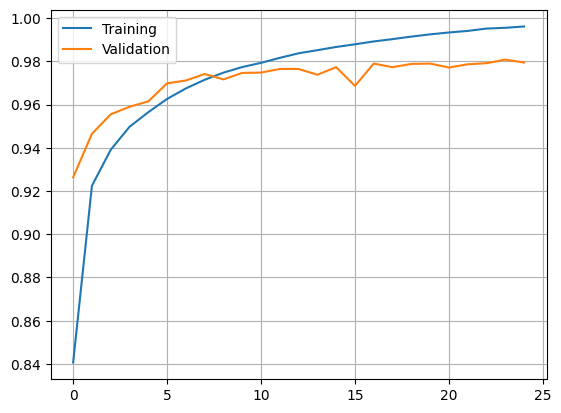

In [43]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.legend()
plt.grid()


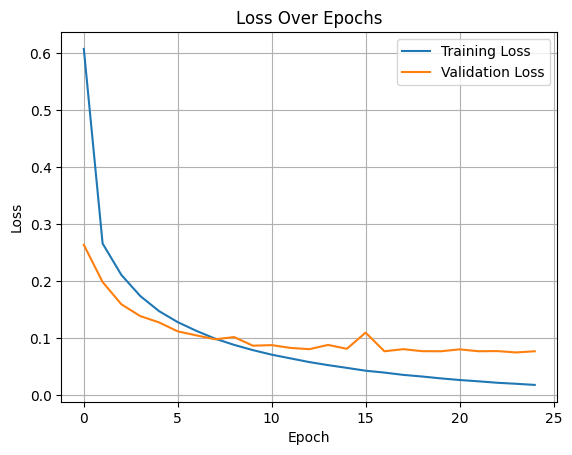

In [44]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid()
plt.show()